<h1><center>CodeAlpha Iris Flower Classification:</h1>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

<h2>Loading Dataset:</h2>

In [2]:
df = pd.read_csv("Iris.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


<h2>Reviewing dataset:</h2>

In [4]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


<h2>Checking dataset Dimensions:</h2>

In [5]:
print("Dataset Shape :", df.shape)

Dataset Shape : (150, 6)


<h2>Checking Column Information:</h2>

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


<h2>Checking Statistical information:</h2>

In [7]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


<h2>Checking Missing Values:</h2>

In [8]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

<h2>Checking the number of flowers in each species:</h2>

In [9]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

<h2>Selecting Input Features:</h2>

In [10]:
X = df.drop(["Id","Species"], axis=1)
X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


<h2>Selecting Target Variable:</h2>

In [11]:
Y = df["Species"]
Y.head()

0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

<h2>Checking the dimemnsions of X and Y:</h2>

In [12]:
print("Input Features Shape :", X.shape)
print("Target Variable Shape :", Y.shape)

Input Features Shape : (150, 4)
Target Variable Shape : (150,)


<h2>Spliting the Training and Testing Data:</h2>

In [13]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.20,
    random_state = 42,
    stratify = Y   
)

<h2>Checking Training and Testing Data Sizes:</h2>

In [15]:
print("Training Features Shape :", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training targets Shape:", Y_train.shape)
print("Testing targets Shape:", Y_test.shape)

Training Features Shape : (120, 4)
Testing Features Shape: (30, 4)
Training targets Shape: (120,)
Testing targets Shape: (30,)


<h2>Checking Species Distribution:</h2>

In [16]:
print("Training Data Distribution :", Y_train.value_counts())
print("\n\nTesting Data Distribution :",Y_test.value_counts())

Training Data Distribution : Species
Iris-setosa        40
Iris-virginica     40
Iris-versicolor    40
Name: count, dtype: int64


Testing Data Distribution : Species
Iris-setosa        10
Iris-virginica     10
Iris-versicolor    10
Name: count, dtype: int64


<h2>Standardizing the Data:</h2>

In [17]:
Scaler = StandardScaler()
X_train_Scaled = Scaler.fit_transform(X_train)
X_test_Scaled = Scaler.transform(X_test)

In [18]:
X_train_Scaled

array([[-1.72156775, -0.32483982, -1.34703555, -1.32016847],
       [-1.12449223, -1.22612948,  0.41429037,  0.65186742],
       [ 1.14439475, -0.55016223,  0.58474127,  0.25746024],
       [-1.12449223,  0.12580502, -1.29021859, -1.45163753],
       [-0.40800161, -1.22612948,  0.13020555,  0.12599118],
       [ 0.54731923, -1.22612948,  0.6983752 ,  0.91480554],
       [-0.2885865 , -0.77548465,  0.24383948,  0.12599118],
       [ 0.54731923, -0.55016223,  0.75519216,  0.3889293 ],
       [ 2.21913069, -0.0995174 ,  1.32336182,  1.44068178],
       [ 2.21913069,  1.70306192,  1.66426361,  1.30921272],
       [ 2.09971558, -0.0995174 ,  1.60744665,  1.17774366],
       [ 0.18907392, -0.32483982,  0.41429037,  0.3889293 ],
       [-1.00507713, -2.35274155, -0.15387928, -0.268416  ],
       [-0.04975629, -0.77548465,  0.18702251, -0.268416  ],
       [-0.04975629, -1.00080706,  0.13020555, -0.00547788],
       [-1.36332244,  0.35112743, -1.23340162, -1.32016847],
       [-0.88566202,  1.

In [19]:
X_test_Scaled

array([[-1.72156775, -0.0995174 , -1.40385252, -1.32016847],
       [ 0.30848902, -0.0995174 ,  0.64155823,  0.78333648],
       [-1.12449223, -1.45145189, -0.26751321, -0.268416  ],
       [-1.00507713, -1.67677431, -0.26751321, -0.268416  ],
       [-1.72156775,  0.35112743, -1.40385252, -1.32016847],
       [ 0.54731923,  0.57644985,  0.5279243 ,  0.52039836],
       [-1.48273754,  1.25241709, -1.57430342, -1.32016847],
       [-0.52741671,  0.80177226, -1.17658466, -1.32016847],
       [ 0.78614944, -0.0995174 ,  0.81200913,  1.0462746 ],
       [-0.52741671, -0.0995174 ,  0.41429037,  0.3889293 ],
       [ 1.74147027, -0.32483982,  1.43699575,  0.78333648],
       [ 1.26380985,  0.12580502,  0.75519216,  1.44068178],
       [ 0.78614944, -0.0995174 ,  1.15291092,  1.30921272],
       [ 0.66673433,  0.35112743,  0.41429037,  0.3889293 ],
       [-1.00507713,  0.80177226, -1.29021859, -1.32016847],
       [-1.00507713,  0.57644985, -1.34703555, -1.32016847],
       [-0.04975629,  2.

In [20]:
print("Scaled Training Data Shape :", X_train_Scaled.shape)
print("Scaled Testing Data Shape :", X_test_Scaled.shape)

Scaled Training Data Shape : (120, 4)
Scaled Testing Data Shape : (30, 4)


<h2>Creating the KNN Model:</h2>

In [21]:
Knn_model = KNeighborsClassifier(n_neighbors = 5)
print(Knn_model)

KNeighborsClassifier()


<h2>Training the Model:</h2>

In [22]:
Knn_model.fit(X_train_Scaled, Y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


<h2>Generating Predictions:</h2>

In [23]:
Y_pred = Knn_model.predict(X_test_Scaled)
print("Predicted Species :", Y_pred)

Predicted Species : ['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']


<h2>Comparing Predictions with Actual Species:</h2>

In [24]:
Comparison = pd.DataFrame({
    "Actual Species" : Y_test.values,
    "Predicted Species" : Y_pred
})
Comparison

,Actual Species,Predicted Species
0,Iris-setosa,Iris-setosa
1,Iris-virginica,Iris-virginica
2,Iris-versicolor,Iris-versicolor
3,Iris-versicolor,Iris-versicolor
4,Iris-setosa,Iris-setosa
5,Iris-versicolor,Iris-versicolor
6,Iris-setosa,Iris-setosa
7,Iris-setosa,Iris-setosa
8,Iris-virginica,Iris-virginica
9,Iris-versicolor,Iris-versicolor


<h2>Calculating Model's Accuracy:</h2>

In [25]:
accuracy = accuracy_score(Y_test, Y_pred)
print("Model's Accuracy Percentage :", accuracy*100)

Model's Accuracy Percentage : 93.33333333333333


<h2>Creating Confusion Matrix:</h2>

In [26]:
cm = confusion_matrix(Y_test, Y_pred)
print("Confusion Matrix :",cm)

Confusion Matrix : [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


<h2>Visualizing the Confusion Matrix:</h2>

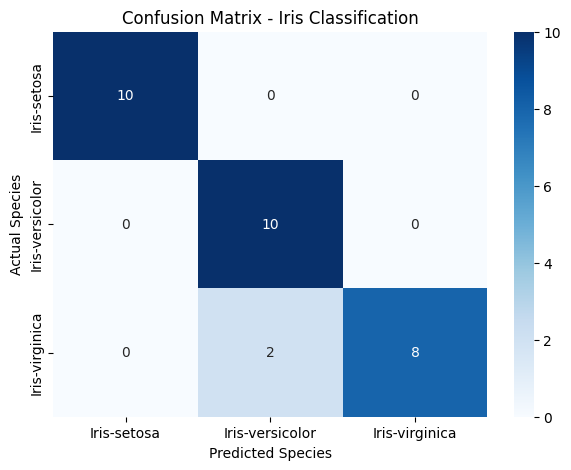

In [27]:
# Create confusion matrix heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Iris-setosa", "Iris-versicolor", "Iris-virginica"],
    yticklabels=["Iris-setosa", "Iris-versicolor", "Iris-virginica"]
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - Iris Classification")

plt.show()

<h2>Classification Report:</h2>

In [28]:
report = classification_report(Y_test, Y_pred)
print("Classification Report :", report)

Classification Report :                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



## Key Findings :

1. The Iris dataset contains 150 flower records and four numerical measurement features.

2. The dataset contains three species: Iris-setosa, Iris-versicolor, and Iris-virginica, with 50 records for each species.

3. No missing values were found during data exploration.

4. The dataset was divided into 80% training data and 20% testing data.

5. StandardScaler was used to standardize the numerical features before applying KNN.

6. The KNN model was trained using 5 nearest neighbors.

7. The model achieved 93.33% accuracy on the testing dataset.

8. The confusion matrix showed that two Iris-virginica flowers were incorrectly classified as Iris-versicolor.

## Recommendations :

1. **Experiment with different K values:** Test different numbers of neighbors, such as 3, 5, 7, and 9, to compare model performance.

2. **Compare different algorithms:** Try other classification algorithms, such as Decision Tree, Logistic Regression, and Support Vector Machine.

3. **Use cross-validation:** Apply cross-validation to evaluate how consistently the model performs across different data splits.

4. **Improve species classification:** Further investigate the confusion between Iris-versicolor and Iris-virginica.

5. **Compare evaluation metrics:** Consider accuracy, precision, recall, and F1-score together instead of relying only on accuracy.

These improvements could help identify a model that performs more consistently on unseen flower measurements.

## Conclusion :

In this project, I developed a machine learning classification model to predict Iris flower species using the K-Nearest Neighbors (KNN) algorithm.

The dataset contained 150 records with four flower measurements: sepal length, sepal width, petal length, and petal width.

After exploring and preprocessing the dataset, I divided it into training and testing sets. I standardized the features and trained the KNN model using 5 nearest neighbors.

The model achieved **93.33% accuracy** on the testing dataset, correctly classifying 28 out of 30 flowers.

The confusion matrix showed that the model correctly classified all Iris-setosa and Iris-versicolor test samples, while two Iris-virginica samples were predicted as Iris-versicolor.

Overall, this project helped me understand the basic machine learning workflow, including data exploration, preprocessing, model training, prediction, and evaluation.